# ERA5 vs Published Ground-Based Wind Speed: Hour-by-Hour Aligned Comparison

This notebook performs a direct hour-by-hour comparison between **ERA5 10m wind speed** and **ALMA ground-based weather station observations** for the years 2001 and 2002. 

Unlike comparisons using monthly averages, this notebook **only compares periods where valid ground-based observations exist** (removing gaps) and matches them to the nearest hourly ERA5 record. This guarantees that both datasets have the exact same number of corresponding points and cover identical time intervals.

In [1]:
# ============================================================
# 1. IMPORTS & CONFIGURATION
# ============================================================
import os
import glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
print("Libraries loaded successfully! ✔")

Libraries loaded successfully! ✔


In [2]:
# ============================================================
# 2. LOAD PUBLISHED GROUND-BASED DATA
# ============================================================
pub_path = r"../data/exports/alma_published_timeseries.csv"
df_pub = pd.read_csv(pub_path, parse_dates=['datetime'])

# Drop rows with missing speed values (Column 7 / 'speed' is wind speed in m/s)
df_pub = df_pub.dropna(subset=['speed'])
print(f"Loaded {len(df_pub):,} valid ground-based hourly records.")
print(df_pub[['datetime', 'speed', 'direction']].head())

Loaded 15,632 valid ground-based hourly records.
             datetime  speed  direction
0 2001-01-01 00:00:00    9.8      268.0
1 2001-01-01 01:00:00    6.6      260.0
2 2001-01-01 02:00:00    3.7      271.0
3 2001-01-01 03:00:00    1.6      301.0
4 2001-01-01 04:00:00    0.2      313.0


In [3]:
# ============================================================
# 3. LOAD ERA5 DATA FOR ALMA SITE
# ============================================================
ALMA_LAT = -23.029
ALMA_LON = -67.755

chile_files = sorted(glob.glob(r"../data/raw/chile/chile_*.nc"))
print(f"Found {len(chile_files)} ERA5 NetCDF files.")

era5_records = []
for f in chile_files:
    with xr.open_dataset(f) as ds:
        # Extract nearest grid point to ALMA site
        point_ds = ds.sel(latitude=ALMA_LAT, longitude=ALMA_LON, method='nearest')
        u10 = point_ds['u10'].values
        v10 = point_ds['v10'].values
        # Calculate 10m wind speed in m/s from components
        ws10 = np.sqrt(u10**2 + v10**2)
        
        df_pt = pd.DataFrame({
            'datetime': point_ds['valid_time'].values,
            'era5_speed': ws10
        })
        era5_records.append(df_pt)

df_era5 = pd.concat(era5_records, ignore_index=True)
print(f"Loaded {len(df_era5):,} ERA5 hourly records.")
print(df_era5.head())

Found 24 ERA5 NetCDF files.
Loaded 17,520 ERA5 hourly records.
             datetime  era5_speed
0 2001-01-01 00:00:00    3.589680
1 2001-01-01 01:00:00    1.797550
2 2001-01-01 02:00:00    1.867238
3 2001-01-01 03:00:00    1.000621
4 2001-01-01 04:00:00    0.164233


In [4]:
# ============================================================
# 4. ALIGN DATASETS (INNER JOIN ON DATETIME)
# ============================================================
# This ensures we only compare timestamps that exist in both datasets
merged_df = pd.merge(df_pub, df_era5, on='datetime', how='inner')
merged_df = merged_df.dropna(subset=['speed', 'era5_speed'])
merged_df = merged_df.sort_values('datetime').reset_index(drop=True)

print(f"Aligned dataset size: {len(merged_df):,} records.")
print(f"Temporal coverage: {merged_df['datetime'].min()} to {merged_df['datetime'].max()}")

Aligned dataset size: 15,632 records.
Temporal coverage: 2001-01-01 00:00:00 to 2002-12-31 23:00:00


In [6]:
# ============================================================
# 5. CALCULATE COMPARISON METRICS
# ============================================================
diff = merged_df['era5_speed'] - merged_df['speed']
rmse = np.sqrt((diff ** 2).mean())
bias = diff.mean()
mae = diff.abs().mean()
corr = merged_df['speed'].corr(merged_df['era5_speed'])

print("--- Aligned Wind Speed Comparison Metrics ---")
print(f"Mean Ground-Based Speed : {merged_df['speed'].mean():.4f} m/s")
print(f"Mean ERA5 Speed         : {merged_df['era5_speed'].mean():.4f} m/s")
print(f"Mean Bias Error (MBE)   : {bias:.4f} m/s (Negative means ERA5 underestimates)")
print(f"Mean Absolute Error (MAE): {mae:.4f} m/s")
print(f"Root Mean Sq. Error (RMSE): {rmse:.4f} m/s")
print(f"Pearson Correlation     : {corr:.4f}")

--- Aligned Wind Speed Comparison Metrics ---
Mean Ground-Based Speed : 6.5501 m/s
Mean ERA5 Speed         : 2.4875 m/s
Mean Bias Error (MBE)   : -4.0626 m/s (Negative means ERA5 underestimates)
Mean Absolute Error (MAE): 4.1247 m/s
Root Mean Sq. Error (RMSE): 5.0299 m/s
Pearson Correlation     : 0.6734


In [7]:
# ============================================================
# 6. OVERALL PERCENTILE COMPARISON
# ============================================================
percentiles = [50, 90, 95, 99]
pub_pcts = [merged_df['speed'].quantile(p/100) for p in percentiles]
era5_pcts = [merged_df['era5_speed'].quantile(p/100) for p in percentiles]

df_pct = pd.DataFrame({
    'Percentile': [f'P{p}' for p in percentiles],
    'Ground-Based (m/s)': pub_pcts,
    'ERA5 (m/s)': era5_pcts,
    'Difference (m/s)': [e - g for g, e in zip(pub_pcts, era5_pcts)],
    'Ratio (ERA5/Ground)': [e / g if g != 0 else np.nan for g, e in zip(pub_pcts, era5_pcts)]
})
print("--- Percentile Comparison Table ---")
print(df_pct.to_string(index=False))

--- Percentile Comparison Table ---
Percentile  Ground-Based (m/s)  ERA5 (m/s)  Difference (m/s)  Ratio (ERA5/Ground)
       P50                 6.0    1.867969         -4.132031             0.311328
       P90                11.8    5.789335         -6.010665             0.490622
       P95                13.6    6.546185         -7.053815             0.481337
       P99                17.6    8.061701         -9.538299             0.458051


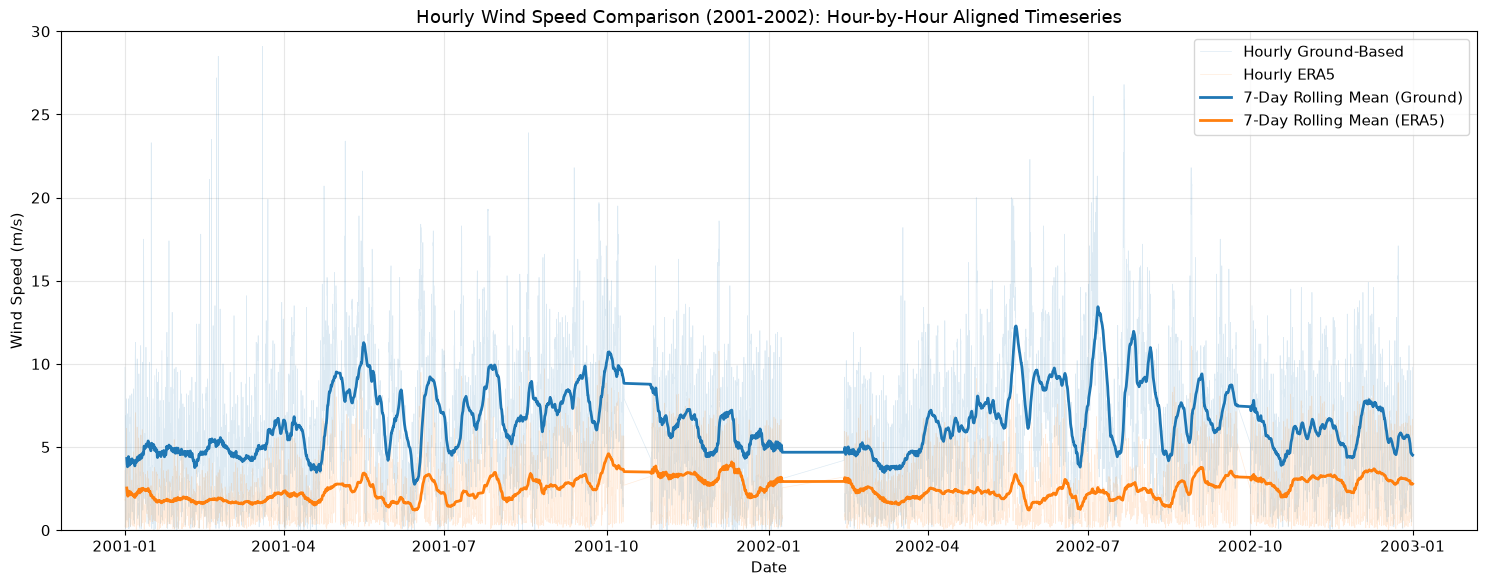

In [8]:
# ============================================================
# 7. PLOT TIME SERIES WITH 7-DAY ROLLING AVERAGE
# ============================================================
plt.figure(figsize=(15, 6))
# Plot hourly speeds in faint color to show raw variance
plt.plot(merged_df['datetime'], merged_df['speed'], color='#1f77b4', alpha=0.15, label='Hourly Ground-Based', linewidth=0.5)
plt.plot(merged_df['datetime'], merged_df['era5_speed'], color='#ff7f0e', alpha=0.15, label='Hourly ERA5', linewidth=0.5)

# 7-day rolling average (aligned hourly data points)
# Note: since 1 week is ~168 hours, we roll by 168 observations
roll_window = 168
plt.plot(merged_df['datetime'], merged_df['speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#1f77b4', label='7-Day Rolling Mean (Ground)', linewidth=2.0)
plt.plot(merged_df['datetime'], merged_df['era5_speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#ff7f0e', label='7-Day Rolling Mean (ERA5)', linewidth=2.0)

plt.title('Hourly Wind Speed Comparison (2001-2002): Hour-by-Hour Aligned Timeseries')
plt.xlabel('Date')
plt.ylabel('Wind Speed (m/s)')
plt.legend(loc='upper right')
plt.ylim(0, 30)
plt.tight_layout()
plt.savefig('../data/exports/aligned_timeseries_comparison.png', dpi=150)
plt.show()

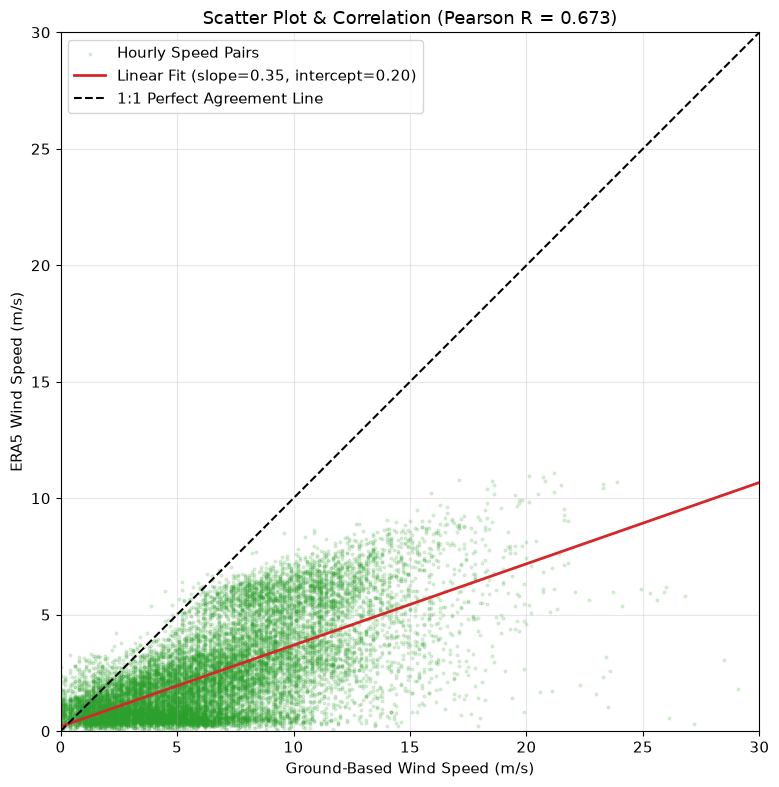

In [9]:
# ============================================================
# 8. SCATTER PLOT AND CORRELATION
# ============================================================
plt.figure(figsize=(8, 8))
plt.scatter(merged_df['speed'], merged_df['era5_speed'], alpha=0.15, s=4, color='#2ca02c', label='Hourly Speed Pairs')

# Fit a trend line
slope, intercept = np.polyfit(merged_df['speed'], merged_df['era5_speed'], 1)
x_vals = np.linspace(0, 30, 100)
plt.plot(x_vals, slope * x_vals + intercept, color='#d62728', linewidth=2.0, 
         label=f'Linear Fit (slope={slope:.2f}, intercept={intercept:.2f})')

# Add 1:1 reference line
plt.plot([0, 30], [0, 30], 'k--', label='1:1 Perfect Agreement Line', linewidth=1.5)

plt.title(f'Scatter Plot & Correlation (Pearson R = {corr:.3f})')
plt.xlabel('Ground-Based Wind Speed (m/s)')
plt.ylabel('ERA5 Wind Speed (m/s)')
plt.xlim(0, 30)
plt.ylim(0, 30)
plt.gca().set_aspect('equal', adjustable='box')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('../data/exports/aligned_scatter_correlation.png', dpi=150)
plt.show()

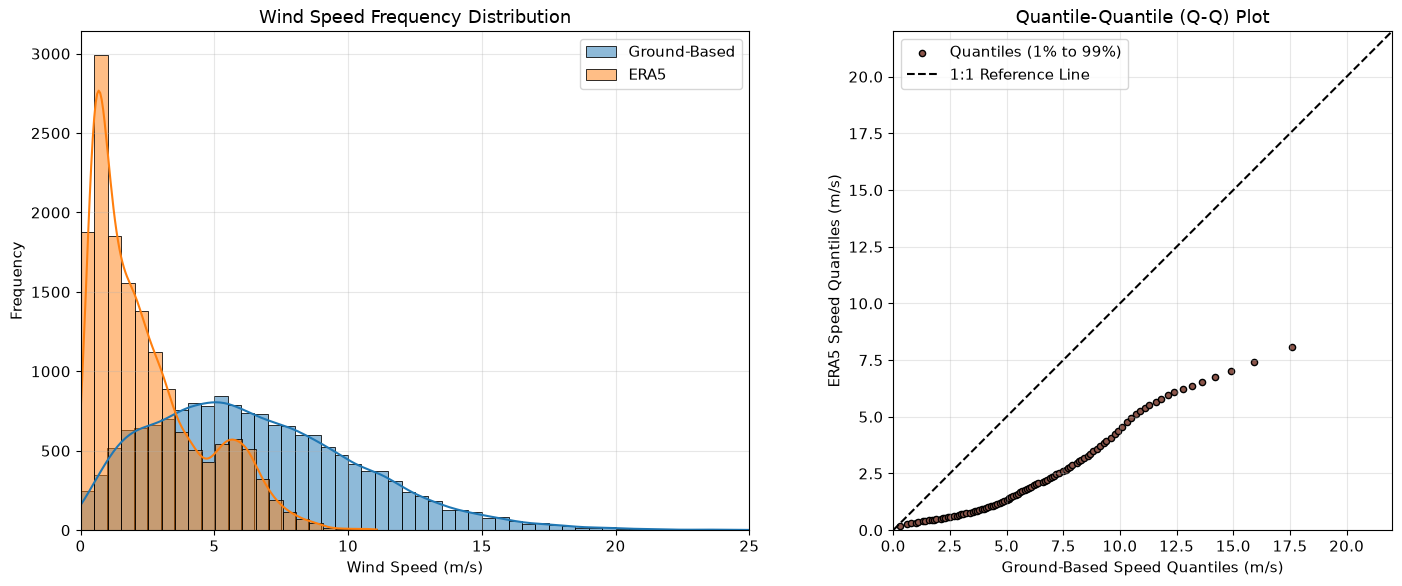

In [10]:
# ============================================================
# 9. DISTRIBUTION COMPARISON (HISTOGRAMS & Q-Q PLOT)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Histograms / KDEs
sns.histplot(merged_df['speed'], color='#1f77b4', alpha=0.5, label='Ground-Based', kde=True, binwidth=0.5, ax=axes[0])
sns.histplot(merged_df['era5_speed'], color='#ff7f0e', alpha=0.5, label='ERA5', kde=True, binwidth=0.5, ax=axes[0])
axes[0].set_title('Wind Speed Frequency Distribution')
axes[0].set_xlabel('Wind Speed (m/s)')
axes[0].set_ylabel('Frequency')
axes[0].set_xlim(0, 25)
axes[0].legend()

# Panel B: Quantile-Quantile (Q-Q) Plot
# We plot sorted percentiles from 1 to 99 to check distributional mapping
q_values = np.linspace(0.01, 0.99, 99)
q_pub = merged_df['speed'].quantile(q_values)
q_era5 = merged_df['era5_speed'].quantile(q_values)

axes[1].scatter(q_pub, q_era5, color='#8c564b', edgecolor='k', s=20, label='Quantiles (1% to 99%)')
axes[1].plot([0, 25], [0, 25], 'k--', label='1:1 Reference Line')
axes[1].set_title('Quantile-Quantile (Q-Q) Plot')
axes[1].set_xlabel('Ground-Based Speed Quantiles (m/s)')
axes[1].set_ylabel('ERA5 Speed Quantiles (m/s)')
axes[1].set_xlim(0, 22)
axes[1].set_ylim(0, 22)
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend()

plt.tight_layout()
plt.savefig('../data/exports/aligned_distribution_comparison.png', dpi=150)
plt.show()

--- Aligned Monthly Means (Excluding ground gaps) ---
 year  month  mean_pub  mean_era5  count
 2001      1  4.670917   1.997699    698
 2001      2  4.792920   1.750296    565
 2001      3  5.440557   1.939577    646
 2001      4  6.149067   2.199389    697
 2001      5  7.944653   2.290840    692
 2001      6  6.477437   2.101699    718
 2001      7  7.375672   2.332597    744
 2001      8  6.839481   2.492284    732
 2001      9  8.483472   3.175502    720
 2001     10  8.178400   3.522260    375
 2001     11  5.821702   3.153679    705
 2001     12  5.656618   2.911721    680
 2002      1  4.740936   2.924759    171
 2002      2  4.730491   2.466761    387
 2002      3  4.717410   1.921300    695
 2002      4  6.484444   2.337423    720
 2002      5  8.355930   2.129771    742
 2002      6  7.582560   2.152803    711
 2002      7  9.171774   2.299517    744
 2002      8  6.988022   2.418354    743
 2002      9  7.120330   2.974560    546
 2002     10  5.582679   2.765542    739
 20

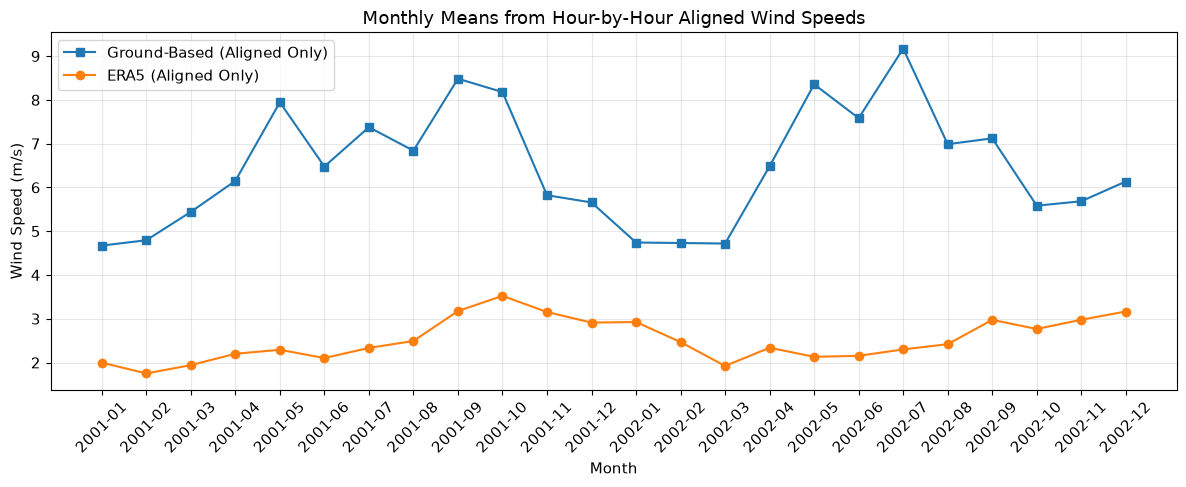

In [11]:
# ============================================================
# 10. RECALCULATED MONTHLY STATS OVER ALIGNED DATA ONLY
# ============================================================
# Group by year/month to see the monthly means *only* on dates where both had valid observations
merged_df['year'] = merged_df['datetime'].dt.year
merged_df['month'] = merged_df['datetime'].dt.month

monthly_aligned = merged_df.groupby(['year', 'month']).agg(
    mean_pub=('speed', 'mean'),
    mean_era5=('era5_speed', 'mean'),
    count=('speed', 'count')
).reset_index()

print("--- Aligned Monthly Means (Excluding ground gaps) ---")
print(monthly_aligned.to_string(index=False))

# Plot monthly means
plt.figure(figsize=(12, 5))
monthly_aligned['date_str'] = monthly_aligned['year'].astype(str) + '-' + monthly_aligned['month'].astype(str).str.zfill(2)
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_pub'], marker='s', color='#1f77b4', label='Ground-Based (Aligned Only)')
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_era5'], marker='o', color='#ff7f0e', label='ERA5 (Aligned Only)')
plt.title('Monthly Means from Hour-by-Hour Aligned Wind Speeds')
plt.xlabel('Month')
plt.ylabel('Wind Speed (m/s)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../data/exports/aligned_monthly_means.png', dpi=150)
plt.show()